# Cumulant (cluster-expansion) coefficients along a TFI quench

Quantum quench of the transverse-field Ising model $H = -J\sum ZZ - g\sum X$ on an open chain: start in the ground state at $g_i$, evolve exactly under $H(g_f)$, and track how the Walsh-Hadamard cluster-expansion ("cumulant") coefficients of $\log|\psi(t)|$ evolve in time.

In [3]:
import os
import sys
sys.path.append('../ClusterExpansion/')
sys.path.append('.')

import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import netket as nk

import cluster_expansion as ce
import ed_definitions as ed

## Quench parameters (modifiable)

In [56]:
L = 10
J = 1.0
J2 = 0
gz = -0.0
g_i = 1.5
g_f = 0.1
theta = 0.45*np.pi# -0.01
pbc = False
gfmax = 2.0
t_max = 0.8
dt = 0.01
times = np.arange(0, t_max + dt / 2, dt)
len(times)

81

## Build pre- and post-quench Hamiltonians

In [57]:
_, hi, H_i = ed.build_TFI_hamiltonian_2(L, g_i, J, J2,theta=theta, pbc=pbc)
_, _, H_f = ed.build_TFI_hamiltonian_2(L, g_f, J, J2,theta=theta, pbc=pbc)

In [58]:
E0, psi0 = ed.ground_state(H_i)
E0

np.float64(-16.53525494675918)

## Full exact diagonalization of the post-quench Hamiltonian, then exact time evolution

In [59]:
evals, evecs = ed.full_diagonalization(H_f)
psi_t = ed.evolve_state(evals, evecs, psi0, times)
psi_t.shape

(81, 1024)

In [60]:
# sanity checks: starts at psi0, stays normalized
print(np.allclose(psi_t[0], psi0))
print(np.max(np.abs(np.linalg.norm(psi_t, axis=1) - 1.0)))

True
3.3306690738754696e-16


## Cluster expansion of $\log|\psi(t)|$ at each time step

In [61]:
n_times, dim = psi_t.shape
c_A = np.zeros((n_times, dim))

for k in range(n_times):
    logabs = np.log(np.abs(psi_t[k]))
    c_A[k] = np.real(ce.fwht_coeffs_in_cluster_col_order(logabs, hi))

c_A.shape

(81, 1024)

## Save $c_A(t)$

In [62]:
os.makedirs('../data/cumulants_Fermi_dirac_TDVP', exist_ok=True)
np.savez(
    '../data/cumulants_Fermi_dirac_TDVP/cumulants_quench.npz',
    times=times,
    c_A=c_A,
    L=L, J=J, g_i=g_i, g_f=g_f, pbc=pbc,
)

## Fermi-Dirac fit of $A(c_A)$ at each time step

The right way to read $A$ as "the CE index between $1:2^L$" is as a **rank/count**,
plotted against $\log|c_A|$ (not $|c_A|$ itself, and not the raw
cluster-column-order index). Concretely: sort $|c_A|$ in descending order and
plot rank $A = 1 \ldots 2^L$ against $\log|c_A|$ at that rank.

Two things had to be fixed to get this right:

- **Odd-order coefficients vanish exactly.** `-J\sum ZZ - g\sum X` on an open
  chain has an exact global $\mathbb{Z}_2$ symmetry, so $\log|\psi(s)|$ is
  even under spin flip and every odd-order cluster coefficient (single-site,
  3-body, ...) is exactly zero — floating point noise at the $10^{-15}$
  level, i.e. $\log|c_A| \sim -35$. These are pure numerical noise, not
  signal, and must be excluded before ranking.
- **Once excluded, exactly half the coefficients remain** ($N_\text{real}=512$
  for $L=10$, confirmed numerically at every timestep) — this is exactly
  where the $2^{L-1}=512$ prefactor in the original ansatz comes from.

Plotting rank vs $\log|c_A|$ over just the 512 real coefficients gives a
genuine, well-identified sigmoid:

$$A(\log|c_A|) \approx \dfrac{A_0}{\exp((\log|c_A| - \mu)/T) + 1}$$

In [63]:
def fermi_dirac(x, mu, T):
    return 1024 / (np.exp((x - mu) / T) + 1)

noise_floor = -28.0  # log|c_A| below this is Z2-symmetry-forced machine-precision noise

def rank_vs_logc(c_A_row):
    """Sort |c_A| descending, drop numerical-noise entries, return (log|c_A|, rank)."""
    absvals = np.abs(c_A_row)
    with np.errstate(divide='ignore'):
        log_c_all = np.log(absvals)
    real_sorted = np.sort(absvals[log_c_all > noise_floor])[::-1]
    log_c = np.log(real_sorted)
    rank = np.arange(1, len(real_sorted) + 1)
    return log_c, rank

mu_t = np.full(n_times, np.nan)
T_t = np.full(n_times, np.nan)
n_real_t = np.full(n_times, np.nan)
r2_t = np.full(n_times, np.nan)

p0 = [-10.0, 3.0]
for k in range(n_times):
    log_c, rank = rank_vs_logc(c_A[k])
    n_real_t[k] = len(rank)
    try:
        popt, _ = curve_fit(fermi_dirac, log_c, rank, p0=p0, maxfev=20000)
        mu_t[k], T_t[k] = popt
        p0 = popt  # warm-start next fit

        pred = fermi_dirac(log_c, *popt)
        ss_res = np.sum((rank - pred) ** 2)
        ss_tot = np.sum((rank - rank.mean()) ** 2)
        r2_t[k] = 1 - ss_res / ss_tot
    except RuntimeError:
        pass

np.sum(np.isnan(mu_t)), n_real_t.min(), n_real_t.max()

(np.int64(0), np.float64(1024.0), np.float64(1024.0))

## Verification: $A(c_A)$ and the fit, at $t = 0, 0.3, 0.5$

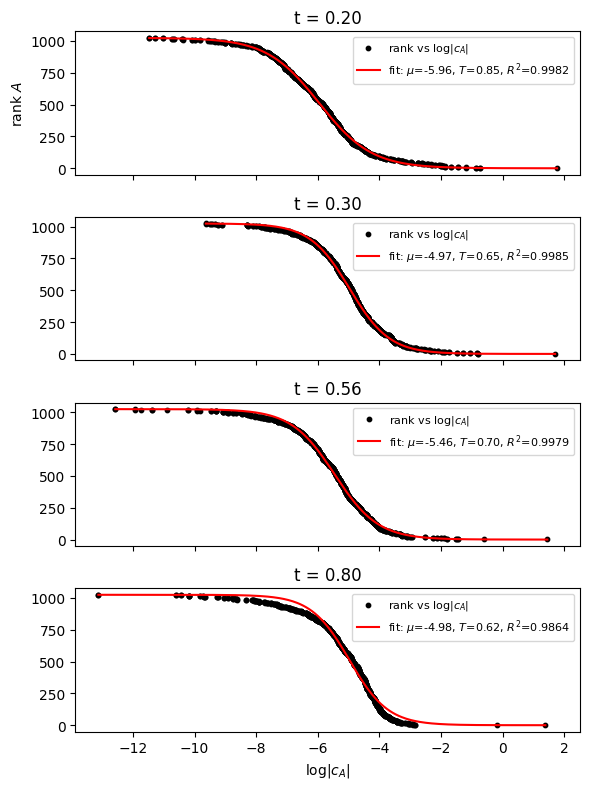

In [64]:
verify_times = [0.2, 0.3, 0.56, 0.8]
verify_idx = [int(round(t / dt)) for t in verify_times]

fig, axs = plt.subplots(len(verify_idx), 1, figsize=(6, 2* len(verify_idx)), sharex=True)
for ax, k in zip(axs, verify_idx):
    log_c, rank = rank_vs_logc(c_A[k])
    ax.scatter(log_c, rank, s=10, color='black', label=r'rank vs $\log|c_A|$')
    xs = np.linspace(log_c.min(), log_c.max(), 300)
    ax.plot(xs, fermi_dirac(xs, mu_t[k], T_t[k]), color='red',
            label=f'fit: $\\mu$={mu_t[k]:.2f}, $T$={T_t[k]:.2f}, $R^2$={r2_t[k]:.4f}')
    ax.set_title(f't = {times[k]:.2f}')
    ax.legend(fontsize=8)
axs[-1].set_xlabel(r'$\log|c_A|$')
axs[0].set_ylabel(r'rank $A$')
plt.tight_layout()
plt.show()

## Plot $\mu(t)$, $T(t)$, and fit quality $R^2(t)$

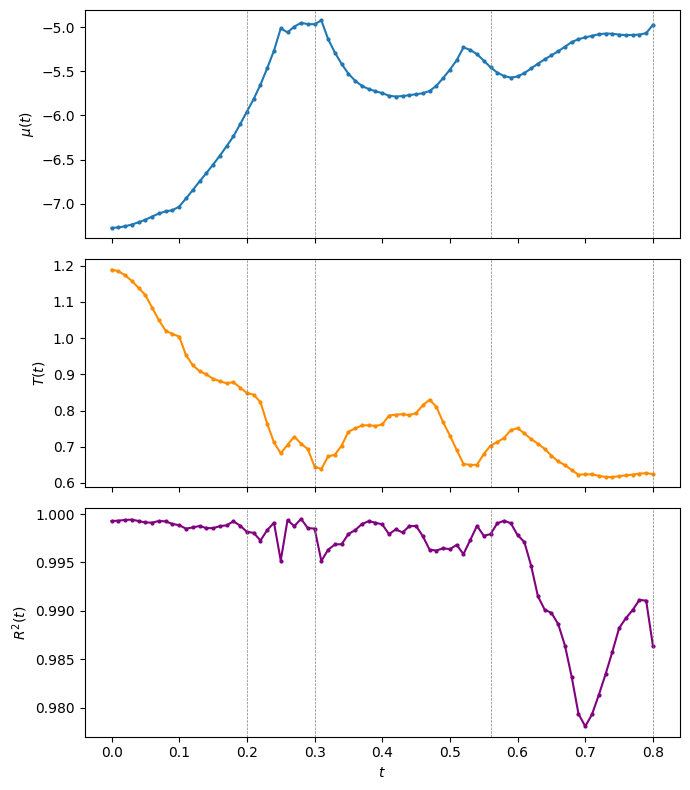

In [65]:
fig, axs = plt.subplots(3, 1, figsize=(7, 8), sharex=True)
axs[0].plot(times, mu_t, marker='o', ms=2)
axs[0].set_ylabel(r'$\mu(t)$')
axs[1].plot(times, T_t, marker='o', ms=2, color='darkorange')
axs[1].set_ylabel(r'$T(t)$')
axs[2].plot(times, r2_t, marker='o', ms=2, color='purple')
axs[2].set_ylabel(r'$R^2(t)$')
axs[2].set_xlabel(r'$t$')
for verify_time in verify_times:
    for ax in axs:
        ax.axvline(verify_time, ymin=0, ymax=1, color='gray', ls='--', lw=0.5)
plt.tight_layout()
plt.show()

## Sweep over $g_f$: heatmap of $\mu(t, g_f)$

Repeat the quench (same $g_i$, same initial state $\psi_0$) for a range of
post-quench fields $g_f$, refitting $\mu(t)$ at each one. The chain's
critical point is at $g=J$.

In [66]:
L = 10
J = 1.0
J2 = 0
gz = -0.0
g_i = 1.5
theta = 0.5*np.pi# -0.01
pbc = False
gfmax = 2.0
t_max = 0.8
dt = 0.01
times = np.arange(0, t_max + dt / 2, dt)
g_f_values = np.linspace(0.1, gfmax, 50)  # modifiable
# g_f_values = np.linspace(0.1, 3, 20)  # modifiable
len(times) * len(g_f_values)

4050

In [67]:
n_times = len(times)
mu_grid = np.full((len(g_f_values), n_times), np.nan)
T_grid = np.full((len(g_f_values), n_times), np.nan)
R2_grid = np.full((len(g_f_values), n_times), np.nan)

psi0 = ed.ground_state(ed.build_TFI_hamiltonian_2(L, g_i, J, J2, gz=gz, theta=theta, pbc=pbc)[2])[1]
for i, g_f_sweep in enumerate(g_f_values):
    _, _, H_f_sweep = ed.build_TFI_hamiltonian_2(L, g_f_sweep, J, J2, gz=gz, theta=theta, pbc=pbc)
    evals_sweep, evecs_sweep = ed.full_diagonalization(H_f_sweep)
    psi_t_sweep = ed.evolve_state(evals_sweep, evecs_sweep, psi0, times)
    n_times, dim = psi_t_sweep.shape

    p0 = [-10.0, 3.0]
    for k in range(n_times):
        logabs = np.log(np.abs(psi_t_sweep[k]))
        c_A_row = np.real(ce.fwht_coeffs_in_cluster_col_order(logabs, hi))
        log_c, rank = rank_vs_logc(c_A_row)
        try:
            popt, _ = curve_fit(fermi_dirac, log_c, rank, p0=p0, maxfev=20000)
            mu_grid[i, k] = popt[0]
            T_grid[i, k] = popt[1]
            R2_grid[i, k] = 1 - np.sum((rank - fermi_dirac(log_c, *popt)) ** 2) / np.sum((rank - rank.mean()) ** 2)
            p0 = popt
        except RuntimeError:
            pass

mu_grid.shape

/tmp/ipykernel_3941574/1799316875.py:2: RuntimeWarning: overflow encountered in exp
  return 1024 / (np.exp((x - mu) / T) + 1)


(50, 81)

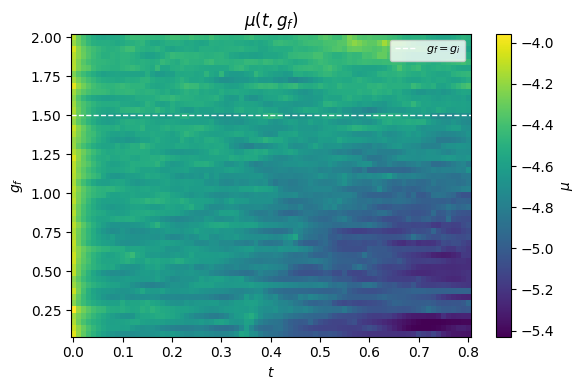

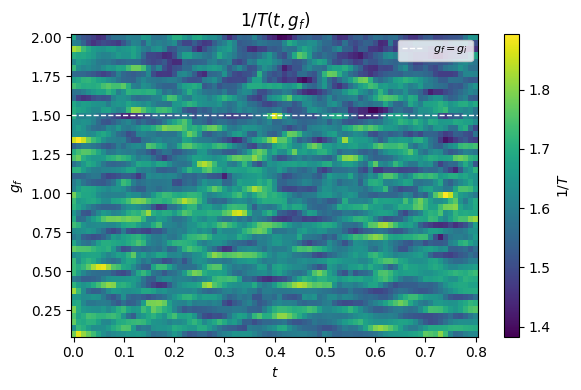

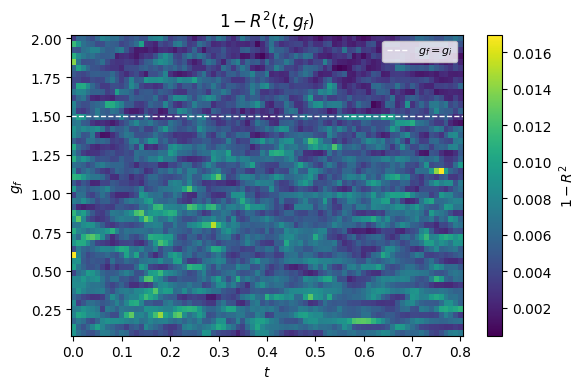

In [68]:
def plot_grid(grid, title, xlabel, ylabel, cbar_label):
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.pcolormesh(times, g_f_values, grid, shading='auto', cmap='viridis')
    ax.axhline(g_i, color='white', ls='--', lw=1, label='$g_f=g_i$')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label=cbar_label)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

plot_grid(mu_grid, r'$\mu(t, g_f)$', '$t$', '$g_f$', r'$\mu$')
plot_grid(1/T_grid, r'$1/T(t, g_f)$', '$t$', '$g_f$', r'$1/T$')
plot_grid(1-R2_grid, r'$1-R^2(t, g_f)$', '$t$', '$g_f$', r'$1-R^2$')

## External data: RBM+TDVP infidelity vs exact, from `/home/nniggemann/shared`

Precomputed infidelity-vs-time data for an actual (non-exact-summation)
RBM+TDVP run: `Inf_RBM_L{L}_g{g_i}_t{t_max}_Ntimes{Ntimes}.pkl`, a dict keyed
`[g_f][alpha][trial] -> infidelity(t)` (6 `g_f` values, 4 hidden densities
`alpha`, 5 trials each, `t` from 0 to 0.99 in steps of 0.01). We select
`alpha=1.0` (matching this repo's own RBM convention) and average over the
5 trials, then plot infidelity$(t, g_f)$ as a heatmap in the same style as
the $\mu(t,g_f)$ heatmap above.

In [17]:
import pickle

L_ext, g_ext, t_ext, Ntimes_ext = 10, 1.5, 1.0, 100
filename = f"/home/nniggemann/shared/Inf_RBM_L{L_ext}_g{g_ext}_t{t_ext}_Ntimes{Ntimes_ext}.pkl"

with open(filename, 'rb') as f:
    inf_rbm_dict = pickle.load(f)

gfs_ext = sorted(inf_rbm_dict.keys())
alphas_ext = sorted(inf_rbm_dict[gfs_ext[0]].keys())
print("g_f values:", gfs_ext)
print("hidden densities (alpha):", alphas_ext)

g_f values: [0.3, 0.5, 0.7, 1.0, 2.0, 3.0]
hidden densities (alpha): [0.5, 1.0, 2.0, 3.0]


In [18]:
alpha_select = 1.0  # matches this notebook's own RBM alpha
n_trials = len(inf_rbm_dict[gfs_ext[0]][alpha_select])
n_t_ext = len(inf_rbm_dict[gfs_ext[0]][alpha_select][0])
times_ext = np.arange(n_t_ext) * 0.01

infid_grid_ext = np.array([
    np.mean([inf_rbm_dict[gf][alpha_select][s] for s in range(n_trials)], axis=0)
    for gf in gfs_ext
])
infid_grid_ext.shape

(6, 100)

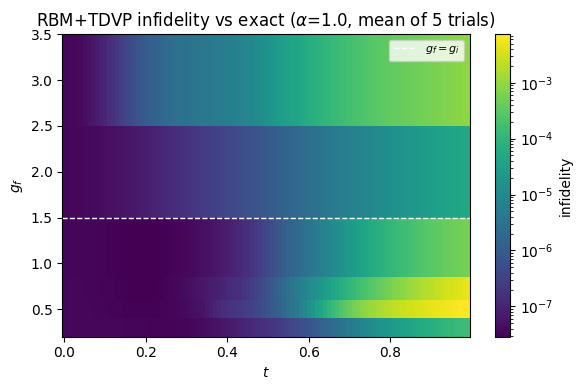

In [19]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.pcolormesh(times_ext, gfs_ext, infid_grid_ext, shading='auto', cmap='viridis', norm=LogNorm())
ax.axhline(g_i, color='white', ls='--', lw=1, label='$g_f=g_i$')
ax.set_xlabel('$t$')
ax.set_ylabel('$g_f$')
ax.set_title(fr'RBM+TDVP infidelity vs exact ($\alpha$={alpha_select}, mean of {n_trials} trials)')
fig.colorbar(im, ax=ax, label='infidelity')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6x6 parameter sweep: $\mu(t, g_f)$ across $(g_z, \theta)$ configurations

`build_TFI_hamiltonian_2` supports a longitudinal field $g_z$ and a basis
rotation $\theta$ beyond the plain TFI model (with $J_2$ held fixed at 0
here). We sweep $g_z \in [0, 1]$ and $\theta \in [0, \pi/2]$ on a 6x6 grid
(36 configurations), and for each one repeat the $\mu(t, g_f)$ heatmap
analysis above with a coarser $g_f$ grid (25 points instead of 50) to keep
the total runtime to roughly 15 minutes.

In [20]:
L = 10
J = 1.0
J2_fixed = 0.0
g_i = 1.5
pbc = False
gfmax = 2.0
t_max = 0.8
dt = 0.01
times = np.arange(0, t_max + dt / 2, dt)
n_times = len(times)

gz_values = np.linspace(0, 1, 6)
theta_values = np.linspace(0, np.pi / 2, 6)
g_f_values_coarse = np.linspace(0.1, gfmax, 25)

len(gz_values) * len(theta_values) * len(g_f_values_coarse) * n_times

72900

In [21]:
import time as _time

mu_grid_66 = np.full((len(gz_values), len(theta_values), len(g_f_values_coarse), n_times), np.nan)

t_start = _time.time()
for gi_idx, gz_val in enumerate(gz_values):
    for th_idx, theta_val in enumerate(theta_values):
        _, hi66, H_i66 = ed.build_TFI_hamiltonian_2(L, g_i, J, J2_fixed, gz=gz_val, theta=theta_val, pbc=pbc)
        psi0_66 = ed.ground_state(H_i66)[1]

        p0 = [-10.0, 3.0]
        for gf_idx, g_f_val in enumerate(g_f_values_coarse):
            _, _, H_f66 = ed.build_TFI_hamiltonian_2(L, g_f_val, J, J2_fixed, gz=gz_val, theta=theta_val, pbc=pbc)
            evals66, evecs66 = ed.full_diagonalization(H_f66)
            psi_t66 = ed.evolve_state(evals66, evecs66, psi0_66, times)

            for k in range(n_times):
                logabs = np.log(np.abs(psi_t66[k]))
                c_A_row = np.real(ce.fwht_coeffs_in_cluster_col_order(logabs, hi66))
                log_c, rank = rank_vs_logc(c_A_row)
                try:
                    popt, _ = curve_fit(fermi_dirac, log_c, rank, p0=p0, maxfev=20000)
                    mu_grid_66[gi_idx, th_idx, gf_idx, k] = popt[0]
                    p0 = popt
                except RuntimeError:
                    pass

        elapsed = _time.time() - t_start
        done = gi_idx * len(theta_values) + th_idx + 1
        print(f"gz={gz_val:.2f} theta={theta_val/np.pi:.2f}pi done ({done}/36), elapsed={elapsed:.1f}s")

print(f"total time: {_time.time()-t_start:.1f}s")

gz=0.00 theta=0.00pi done (1/36), elapsed=17.0s
gz=0.00 theta=0.10pi done (2/36), elapsed=32.4s
gz=0.00 theta=0.20pi done (3/36), elapsed=48.3s
gz=0.00 theta=0.30pi done (4/36), elapsed=64.5s
gz=0.00 theta=0.40pi done (5/36), elapsed=79.2s
gz=0.00 theta=0.50pi done (6/36), elapsed=96.5s
gz=0.20 theta=0.00pi done (7/36), elapsed=112.0s
gz=0.20 theta=0.10pi done (8/36), elapsed=127.7s
gz=0.20 theta=0.20pi done (9/36), elapsed=142.4s
gz=0.20 theta=0.30pi done (10/36), elapsed=158.6s
gz=0.20 theta=0.40pi done (11/36), elapsed=173.5s
gz=0.20 theta=0.50pi done (12/36), elapsed=230.3s


/tmp/ipykernel_3941574/1799316875.py:2: RuntimeWarning: overflow encountered in exp
  return 1024 / (np.exp((x - mu) / T) + 1)


gz=0.40 theta=0.00pi done (13/36), elapsed=323.2s
gz=0.40 theta=0.10pi done (14/36), elapsed=374.8s
gz=0.40 theta=0.20pi done (15/36), elapsed=390.1s
gz=0.40 theta=0.30pi done (16/36), elapsed=430.4s
gz=0.40 theta=0.40pi done (17/36), elapsed=444.6s
gz=0.40 theta=0.50pi done (18/36), elapsed=495.0s
gz=0.60 theta=0.00pi done (19/36), elapsed=528.9s
gz=0.60 theta=0.10pi done (20/36), elapsed=544.0s
gz=0.60 theta=0.20pi done (21/36), elapsed=559.0s
gz=0.60 theta=0.30pi done (22/36), elapsed=573.7s
gz=0.60 theta=0.40pi done (23/36), elapsed=588.8s
gz=0.60 theta=0.50pi done (24/36), elapsed=602.4s
gz=0.80 theta=0.00pi done (25/36), elapsed=616.6s
gz=0.80 theta=0.10pi done (26/36), elapsed=631.5s
gz=0.80 theta=0.20pi done (27/36), elapsed=646.1s
gz=0.80 theta=0.30pi done (28/36), elapsed=666.3s
gz=0.80 theta=0.40pi done (29/36), elapsed=681.0s
gz=0.80 theta=0.50pi done (30/36), elapsed=702.6s
gz=1.00 theta=0.00pi done (31/36), elapsed=717.6s
gz=1.00 theta=0.10pi done (32/36), elapsed=732.4s


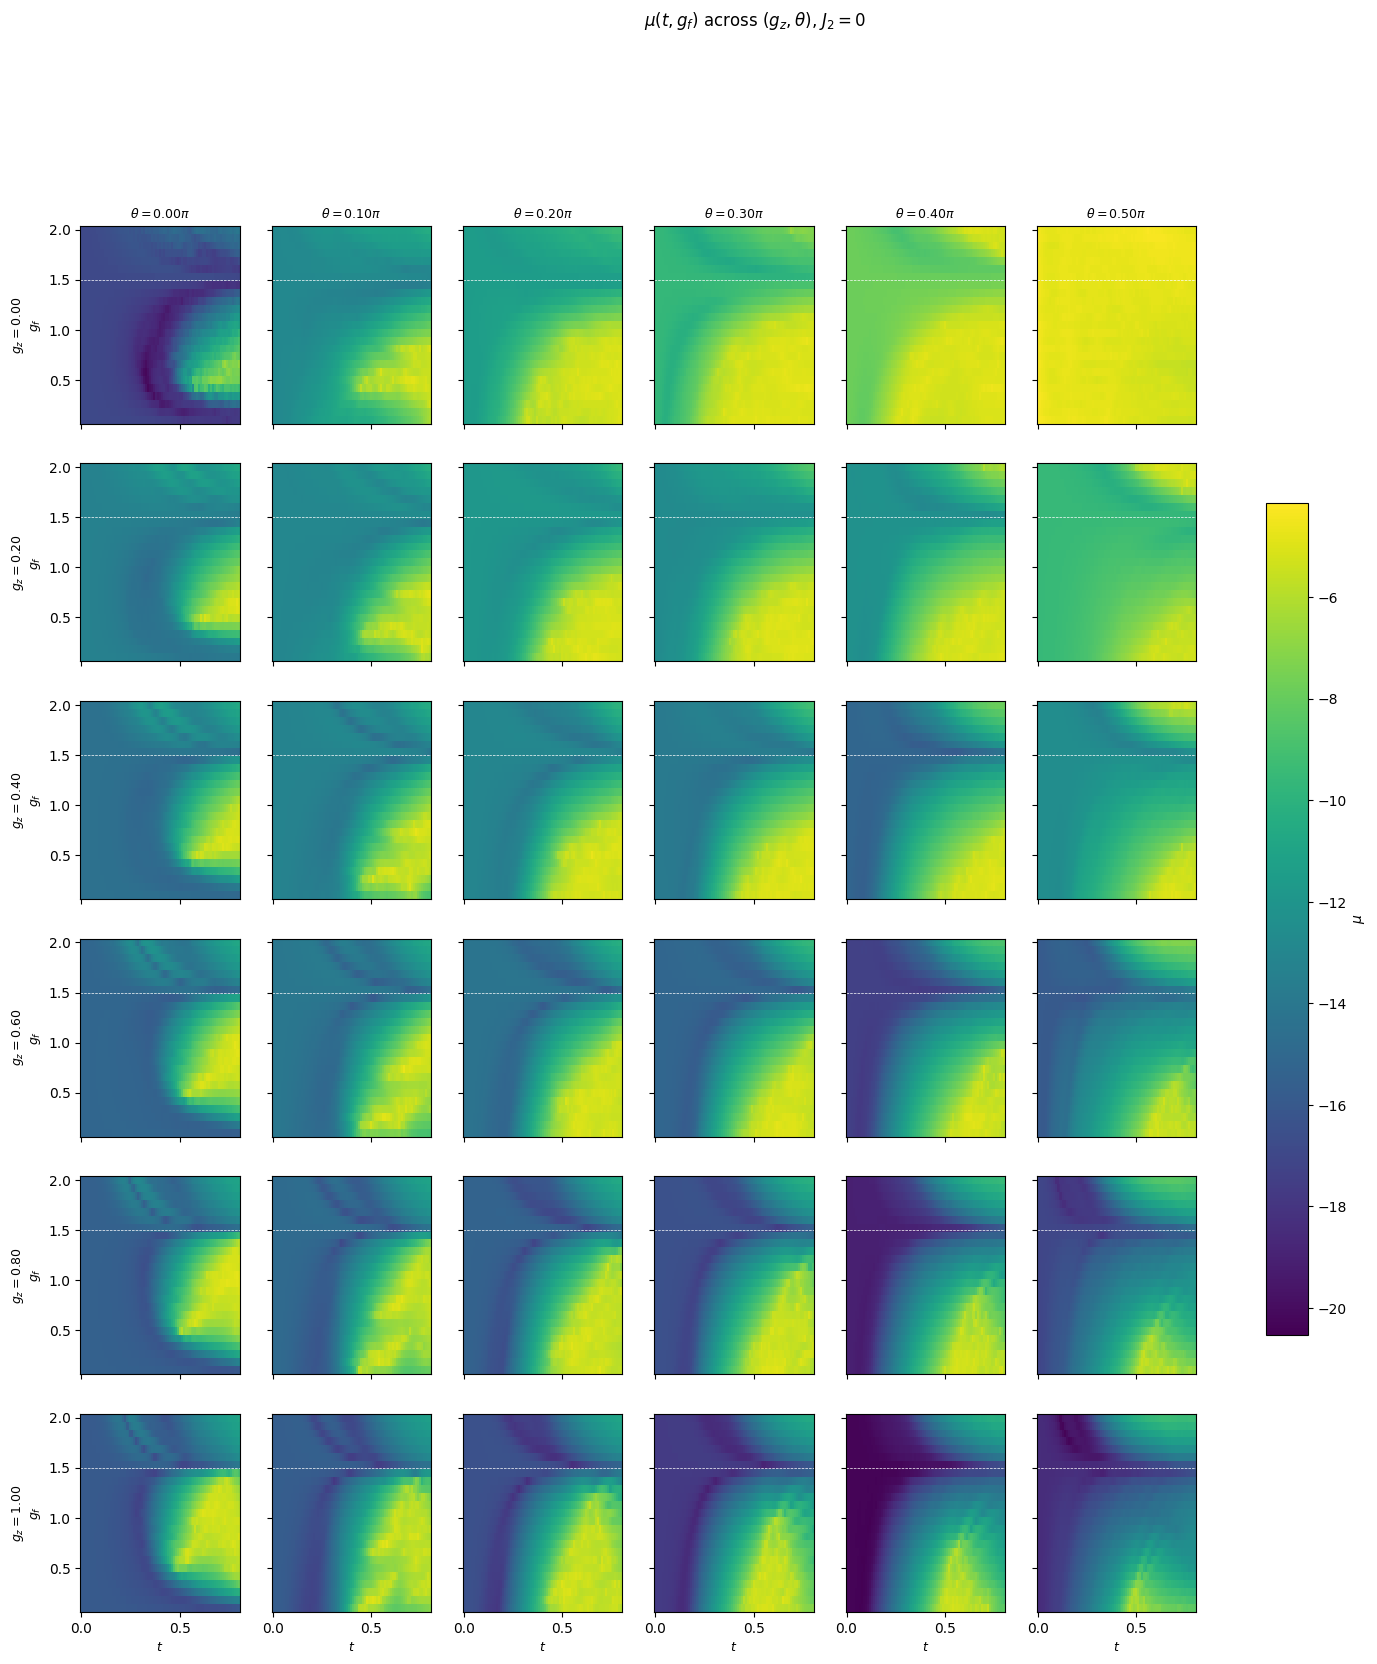

In [22]:
vmin, vmax = np.nanmin(mu_grid_66), np.nanmax(mu_grid_66)

fig, axs = plt.subplots(len(gz_values), len(theta_values),
                         figsize=(3 * len(theta_values), 3 * len(gz_values)),
                         sharex=True, sharey=True)

for gi_idx, gz_val in enumerate(gz_values):
    for th_idx, theta_val in enumerate(theta_values):
        ax = axs[gi_idx, th_idx]
        im = ax.pcolormesh(times, g_f_values_coarse, mu_grid_66[gi_idx, th_idx],
                            shading='auto', cmap='viridis', vmin=vmin, vmax=vmax)
        ax.axhline(g_i, color='white', ls='--', lw=0.5)
        if gi_idx == 0:
            ax.set_title(fr'$\theta={theta_val/np.pi:.2f}\pi$', fontsize=9)
        if th_idx == 0:
            ax.set_ylabel(fr'$g_z={gz_val:.2f}$' + '\n$g_f$', fontsize=9)
        if gi_idx == len(gz_values) - 1:
            ax.set_xlabel('$t$', fontsize=9)

fig.suptitle(r'$\mu(t, g_f)$ across $(g_z, \theta)$, $J_2=0$', y=1.0)
fig.colorbar(im, ax=axs, shrink=0.6, label=r'$\mu$')
plt.show()

## 4x4 parameter sweep: $\mu(t, g_f)$ across $(\theta, J_2)$ configurations (finer $g_f$ grid)

Same recipe, now sweeping $\theta \times J_2$ on a 4x4 grid (16
configurations, $g_z=0$ fixed). With only 16 configurations instead of 36,
there's headroom to use a finer inner $g_f$ grid (40 points instead of 25)
while still running faster overall than the 6x6 sweep above.

In [23]:
gz_fixed2 = 0.0
theta_values2 = np.linspace(0, np.pi / 2, 4)
J2_values2 = np.linspace(0, 1, 4)
g_f_values_fine = np.linspace(0.1, gfmax, 40)

len(theta_values2) * len(J2_values2) * len(g_f_values_fine) * n_times

51840

In [24]:
mu_grid_44 = np.full((len(theta_values2), len(J2_values2), len(g_f_values_fine), n_times), np.nan)

t_start2 = _time.time()
for th_idx, theta_val in enumerate(theta_values2):
    for j2_idx, J2_val in enumerate(J2_values2):
        _, hi44, H_i44 = ed.build_TFI_hamiltonian_2(L, g_i, J, J2_val, gz=gz_fixed2, theta=theta_val, pbc=pbc)
        psi0_44 = ed.ground_state(H_i44)[1]

        p0 = [-10.0, 3.0]
        for gf_idx, g_f_val in enumerate(g_f_values_fine):
            _, _, H_f44 = ed.build_TFI_hamiltonian_2(L, g_f_val, J, J2_val, gz=gz_fixed2, theta=theta_val, pbc=pbc)
            evals44, evecs44 = ed.full_diagonalization(H_f44)
            psi_t44 = ed.evolve_state(evals44, evecs44, psi0_44, times)

            for k in range(n_times):
                logabs = np.log(np.abs(psi_t44[k]))
                c_A_row = np.real(ce.fwht_coeffs_in_cluster_col_order(logabs, hi44))
                log_c, rank = rank_vs_logc(c_A_row)
                try:
                    popt, _ = curve_fit(fermi_dirac, log_c, rank, p0=p0, maxfev=20000)
                    mu_grid_44[th_idx, j2_idx, gf_idx, k] = popt[0]
                    p0 = popt
                except RuntimeError:
                    pass

        elapsed = _time.time() - t_start2
        done = th_idx * len(J2_values2) + j2_idx + 1
        print(f"theta={theta_val/np.pi:.2f}pi J2={J2_val:.2f} done ({done}/16), elapsed={elapsed:.1f}s")

print(f"total time: {_time.time()-t_start2:.1f}s")

theta=0.00pi J2=0.00 done (1/16), elapsed=22.3s
theta=0.00pi J2=0.33 done (2/16), elapsed=45.0s
theta=0.00pi J2=0.67 done (3/16), elapsed=70.2s
theta=0.00pi J2=1.00 done (4/16), elapsed=97.5s


/tmp/ipykernel_3941574/1799316875.py:2: RuntimeWarning: overflow encountered in exp
  return 1024 / (np.exp((x - mu) / T) + 1)


theta=0.17pi J2=0.00 done (5/16), elapsed=120.1s
theta=0.17pi J2=0.33 done (6/16), elapsed=145.6s
theta=0.17pi J2=0.67 done (7/16), elapsed=168.5s
theta=0.17pi J2=1.00 done (8/16), elapsed=191.7s
theta=0.33pi J2=0.00 done (9/16), elapsed=214.2s
theta=0.33pi J2=0.33 done (10/16), elapsed=237.8s
theta=0.33pi J2=0.67 done (11/16), elapsed=261.8s
theta=0.33pi J2=1.00 done (12/16), elapsed=285.6s
theta=0.50pi J2=0.00 done (13/16), elapsed=310.4s
theta=0.50pi J2=0.33 done (14/16), elapsed=334.8s
theta=0.50pi J2=0.67 done (15/16), elapsed=357.5s
theta=0.50pi J2=1.00 done (16/16), elapsed=380.0s
total time: 380.0s


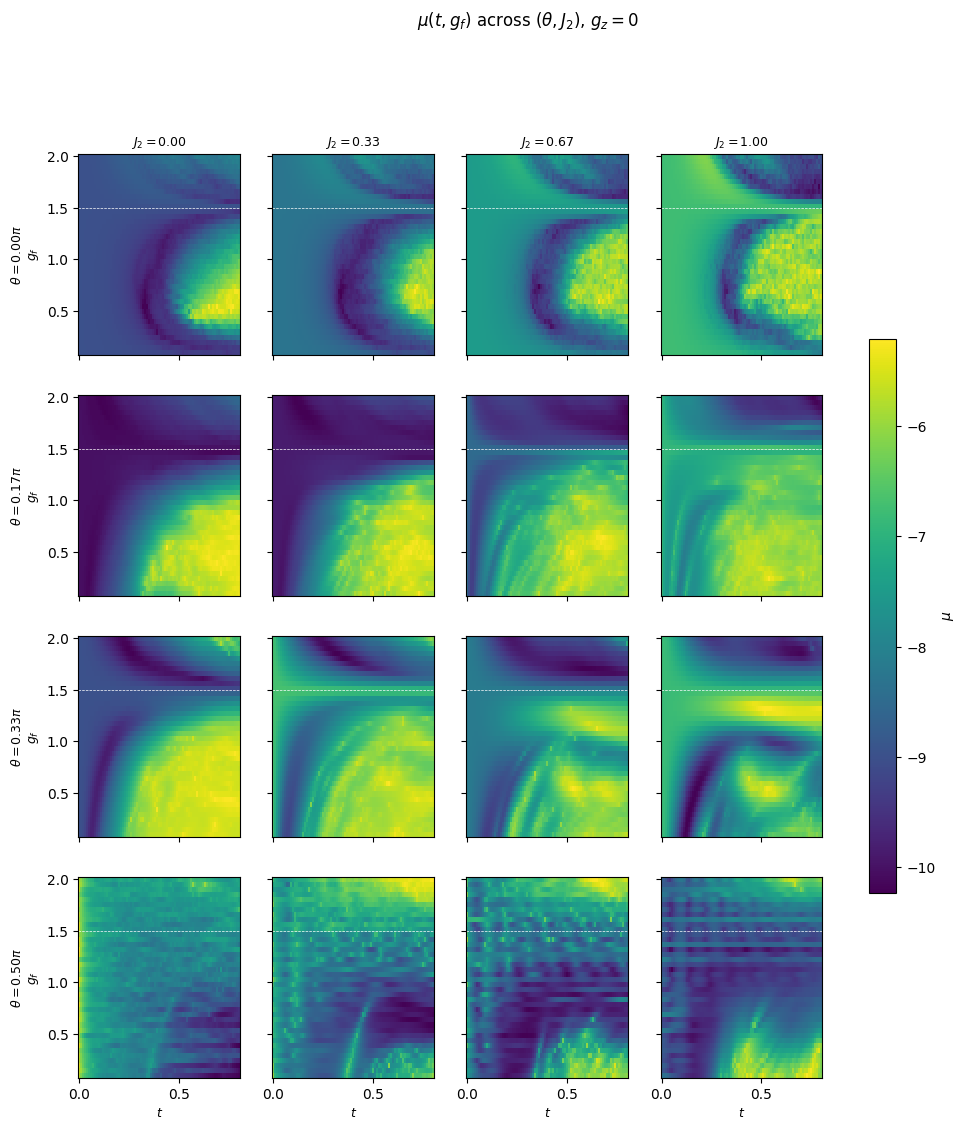

In [27]:
vmin2, vmax2 = np.nanmin(mu_grid_44), np.nanmax(mu_grid_44)

fig, axs = plt.subplots(len(theta_values2), len(J2_values2),
                         figsize=(3 * len(J2_values2), 3 * len(theta_values2)),
                         sharex=True, sharey=True)

for th_idx, theta_val in enumerate(theta_values2):
    for j2_idx, J2_val in enumerate(J2_values2):
        ax = axs[th_idx, j2_idx]
        # im = ax.pcolormesh(times, g_f_values_fine, mu_grid_44[th_idx, j2_idx], shading='auto', cmap='viridis', vmin=vmin2, vmax=vmax2)
        im = ax.pcolormesh(times, g_f_values_fine, mu_grid_44[th_idx, j2_idx],shading='auto', cmap='viridis', )
        ax.axhline(g_i, color='white', ls='--', lw=0.5)
        if th_idx == 0:
            ax.set_title(fr'$J_2={J2_val:.2f}$', fontsize=9)
        if j2_idx == 0:
            ax.set_ylabel(fr'$\theta={theta_val/np.pi:.2f}\pi$' + '\n$g_f$', fontsize=9)
        if th_idx == len(theta_values2) - 1:
            ax.set_xlabel('$t$', fontsize=9)

fig.suptitle(r'$\mu(t, g_f)$ across $(\theta, J_2)$, $g_z=0$', y=1.0)
fig.colorbar(im, ax=axs, shrink=0.6, label=r'$\mu$')
plt.show()